In [2]:
# import the libraries

import numpy as np
import math
import matplotlib.pyplot as plt

# The code till now shows Forward propogation

In [3]:
## Define the Value class

class Value():
    def __init__(self, data, _children=(), _op = '', label = ''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return(f"Value (data={self.data})")

    def __add__(self, other):
        out = Value(self.data + other.data, _children = (self, other), _op = '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        return out

## Code to Visualize the expression

from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format = 'svg', graph_attr = {'rankdir': 'LR'}) ## LR - Left to Right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))   # The id() function returns a unique id for the specified object.

        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f }" % (n.label, n.data, ), shape = 'record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    # if the nodes are in edges
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a * b   ## python will internally call a.__add__(b)
e.label = 'e'

d = e + c
d.label = 'd'

f = Value(-2.0, label = 'f')
L = d * f
L.label = 'L'


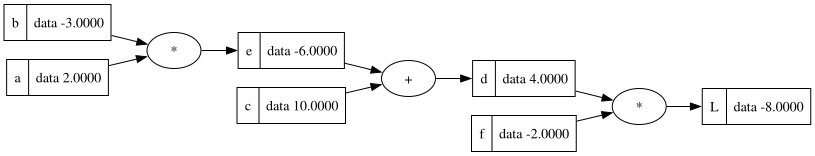

In [4]:
draw_dot(L)

# Adding backpropogation logic to the class.

That means we need to find the derivative of L wrt f, d, e, c, b, and a (in the reverse order)

In neural network setting, we will be very interested in the loss function (L) wrt to the weight of the neural network, so we will be interested to see how the weights of NN impacts the loss function.

So, we will create a new variable in our Class Value, which can store the gradient, let's call it "grad".

In [5]:
class Value():
    def __init__(self, data, _children=(), _op = '', label = ''):
        self.data = data
        self.grad = 0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return(f"Value (data={self.data})")

    def __add__(self, other):
        out = Value(self.data + other.data, _children = (self, other), _op = '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        return out


Here, by default, we assume the gradient is 0. Since, adding a new value should not affect the loss function.

In [6]:
## Let's add grad to our visualization pipeline as well

from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format = 'svg', graph_attr = {'rankdir': 'LR'}) ## LR - Left to Right
    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))   # The id() function returns a unique id for the specified object.

        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad ), shape = 'record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name = uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    # if the nodes are in edges
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [7]:
a = Value(2.0, label = 'a')
b = Value(-3.0, label = 'b')
c = Value(10.0, label = 'c')
e = a * b   ## python will internally call a.__add__(b)
e.label = 'e'

d = e + c
d.label = 'd'

f = Value(-2.0, label = 'f')
L = d * f
L.label = 'L'


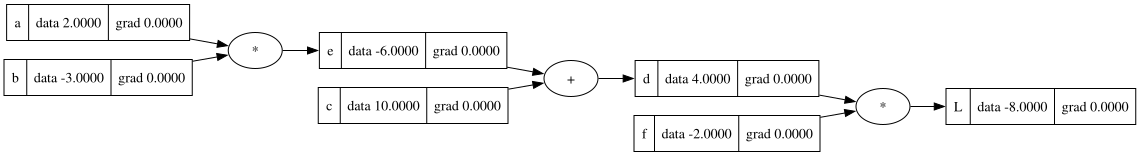

In [8]:
draw_dot(L)

Let's try to fill-in the gradient manually in our graph, based on our calculation.

1. dl/L: What is the derivative of L wrt L? If I change L by a tiny amout h, and see the change wrt L, and then change over h, will be 1.

In [9]:
def lol():
    h = 0.0001
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    
    d = e + c
    d.label = 'd'
    
    f = Value(-2.0, label = 'f')
    L = d * f
    L.label = 'L'
    L1 = L.data

    ## increase a by a tiny amount
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    
    d = e + c
    d.label = 'd'
    
    f = Value(-2.0, label = 'f')
    L = d * f
    L.label = 'L'
    L2 = L.data + h

    print((L2-L1)/h)

In [10]:
lol()

0.9999999999976694


da/dL = 6; dL/dL = 1

In [11]:
L.grad = 1

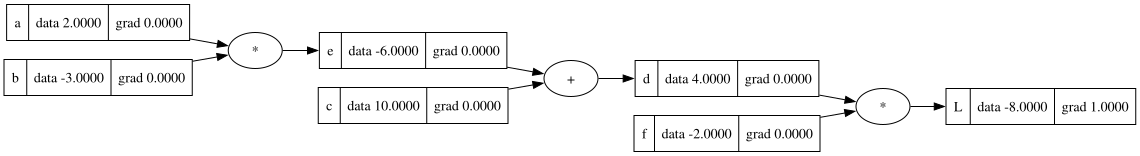

In [12]:
draw_dot(L)

L = d * f

dL/dd = f

(f(x+h) - f(x))/h

((d+h)*f - (d*f))/h

(df + hf - df)/h = hf/h = f

In [13]:
f.grad = d.data
d.grad = f.data

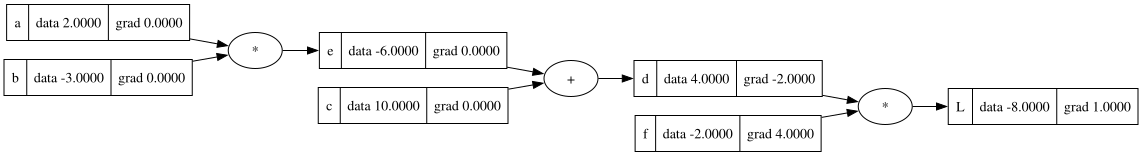

In [14]:
draw_dot(L)

In [15]:
## Let's check the answer in our staging area

def lol():
    h = 0.0001
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    
    d = e + c
    d.label = 'd'
    
    f = Value(-2.0, label = 'f')
    L = d * f
    L.label = 'L'
    L1 = L.data

    ## increase f by a tiny amount
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    
    d = e + c
    d.label = 'd'
    # d.data +=h
    
    f = Value(-2.0, label = 'f')
    f.data +=h
    L = d * f
    L.label = 'L'
    L2 = L.data

    print((L2-L1)/h)

lol()

3.9999999999995595


## This is important, if we understand this node, you understand all the crux of backpropogation.

### we need to derive dL/dc and dL/de

dL / dc

So, we know how L is derived from d and f, and we know how much L is sensitive of d (dL/dd), so how can we derive dL/dc.

What we can do is look at what is dd/dc.

So, d here is e + c, dd/dc = 1

We can also look at the formula-

d = e + c

(f(x+h) - f(x))/h

(e+(c+h) - (e + c))/h

(e + c + h - e -c) /h

h/h = 1

#### Similarly, dd/de = 1.0 (as d = e+c)


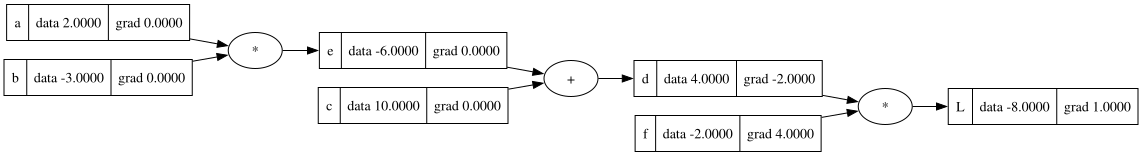

In [16]:
draw_dot(L)

So we have the following:

$$ dd/dc = 1.0 $$
$$ dd/de = 1.0 $$
$$ d = c + e $$

So, we will be using **Chain rule** here:

If a variable `z` depends on the variable `y`, which itself depends on the variable `x`, then `z` depends on `x` as well, via th eintermediate variable `y`. In this case, chain rule is expressed as:

$$ \frac{dz}{dx} = \frac{dz}{dy}.\frac{dy}{dx} $$

**Intuitive explanation: If a car travels 2x as fast as a bicycle, and bicycle is 4x fast as a walking man, then the car travels 2*4 = 8 times as fast as the walking man.**



So, we can derive dL/dc easily:

WANT:

dL / dc

KNOW:

dL / dd

dd / dc


$$ \frac{dL}{dc} = \frac{dL}{dd}.\frac{dd}{dc} $$

So, dL/dc = -2*1 = -2

Because the local derivative of dd/dc is 1, what we are doing here is we just copy over the dL/dd, because dd/dc is 1.0

- So if dL/dd is -2, what is dL/dc, it is the local derivative * -2 = -2.
- So literally what a `+` node does is literally just routes the gradient, because the `+` nodes local derivatives are just 1, so in the chain rule, 1* dL/dd is dL/dd. So the derivative just gets routed to both c and e. 

In [18]:
e.grad = -2.0

In [19]:
c.grad = -2.0

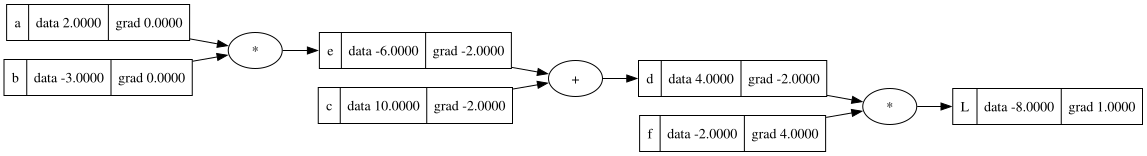

In [20]:
draw_dot(L)

- So here the backgropogation nodes, which is carrying the information of what is the derivative of L w.r.t. all the intermediate nodes, we can imagine like flowing backward through the graph.

- `+` node simply distribute the derivative to all its children node.

In [24]:
def lol():
    h = 0.0001
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    
    d = e + c
    d.label = 'd'
    
    f = Value(-2.0, label = 'f')
    L = d * f
    L.label = 'L'
    L1 = L.data

    ## increase f by a tiny amount
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    e.data +=h
    d = e + c
    d.label = 'd'
    # d.data +=h
    
    f = Value(-2.0, label = 'f')
    #f.data +=h
    L = d * f
    L.label = 'L'
    L2 = L.data

    print((L2-L1)/h)

lol()

-1.9999999999953388


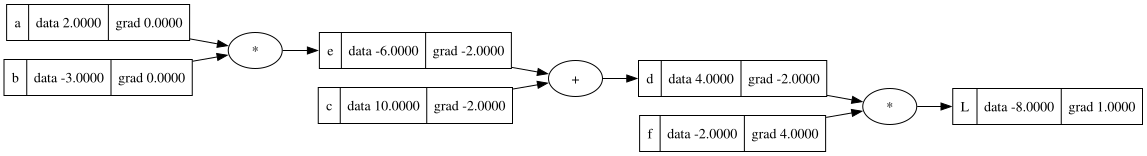

In [26]:
draw_dot(L)

### So let's do the same for dL/da and dL/db.

So we know dL/de = -2
e = a * b

So by chain rule, we know that:
dL / da = dL / de * de / da

So, de / da = b (value) = -3.0


In [27]:
a.grad = -2.0 * -3.0

In [30]:
b.grad = -2.0 * 2.0

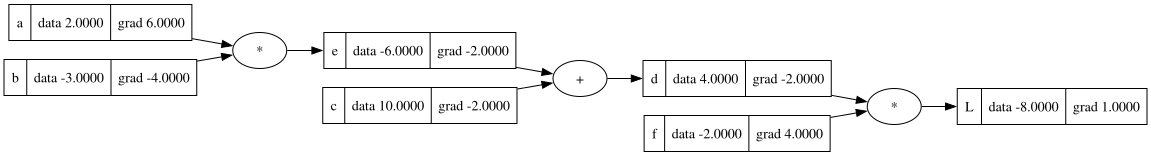

In [31]:
draw_dot(L)

In [38]:
# Let's verify them

def lol():
    h = 0.0001
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    
    d = e + c
    d.label = 'd'
    
    f = Value(-2.0, label = 'f')
    L = d * f
    L.label = 'L'
    L1 = L.data

    ## increase f by a tiny amount
    a = Value(2.0, label = 'a')
    b = Value(-3.0, label = 'b')
    b.data +=h
    c = Value(10.0, label = 'c')
    e = a * b   ## python will internally call a.__add__(b)
    e.label = 'e'
    #e.data +=h
    d = e + c
    d.label = 'd'
    # d.data +=h
    
    f = Value(-2.0, label = 'f')
    #f.data +=h
    L = d * f
    L.label = 'L'
    L2 = L.data

    print((L2-L1)/h)

lol()

-4.000000000008441


#### So, what we have done till now?

All we have done is we iterated through all the nodes one by one, and locally applied the chain rule. We always know what is the derivative of L w.r.t this little output, and then we look at how this output was produced. SO this output was produced through some operations, and we have the pointer to the children nodes of this operation. SO, in this local operation, we know what the local derivative are, and we just multiply them on to the derivatives always. So, we just go through and recursively multiply on the local derivatives, and that's what back propogation is. **it's just recursive application of chain rule backwards though the computation graph**

### Let's see this power in action

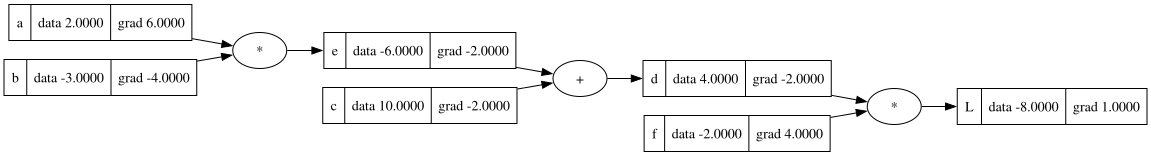

In [39]:
draw_dot(L)

Suppose if I nudge my input so that L should go up, L goes up means we have to go in the direction of the gradient. 

In [40]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

## forward propogation
e = a * b
d = e + c
L = d * f

In [41]:
L

Value (data=-7.286496)

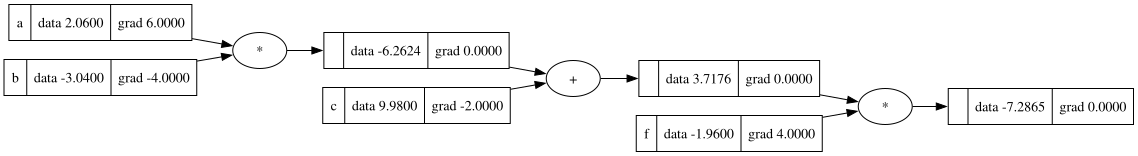

In [42]:
draw_dot(L)